# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [16]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'

    if csv_path.exists():
        return pd.read_csv(csv_path)

    if parquet_path.exists():
        return pd.read_parquet(parquet_path)

    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [17]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [18]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [19]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).

import pandas as pd
import numpy as np

def parse_dates(series, min_success_rate=0.95, dayfirst=True):
    """
    Convertit une série en dates, calcule un report détaillé,
    et lève une ValueError si le taux de réussite est trop faible.
    """

    # 1. Comptage initial
    n_total = len(series)
    n_already_missing = series.isna().sum()

    # 2. Nettoyage léger des chaînes (enlève texte parasite)
    cleaned = (
        series.astype(str)
              .str.replace(r'[^0-9/.\- ]', '', regex=True)
              .str.strip()
              .replace({"": np.nan})
    )

    # 3. Conversion des dates
    converted = pd.to_datetime(cleaned, errors='coerce', dayfirst=dayfirst)

    # 4. Échecs de conversion
    n_failed = converted.isna().sum() - n_already_missing
    success_rate = 1 - (n_failed / n_total)

    # 5. Min / max sur les dates valides
    valid_dates = converted.dropna()
    min_date = valid_dates.min() if not valid_dates.empty else None
    max_date = valid_dates.max() if not valid_dates.empty else None

    # 6. Report
    report = {
        "n_total": n_total,
        "n_already_missing": n_already_missing,
        "n_failed": n_failed,
        "success_rate": success_rate,
        "min_date": min_date,
        "max_date": max_date
    }

    # 7. Vérification du seuil
    if success_rate < min_success_rate:
        raise ValueError(
            f"Taux de réussite {success_rate:.3f} < seuil {min_success_rate}"
        )

    return converted, report


# -----------------------------
# TEST SUR TA COLONNE
# -----------------------------

# On baisse le seuil pour inspecter les données
order_dates, report = parse_dates(raw_sales['date_commande'], min_success_rate=0.20)

print("=== REPORT ===")
print(report)

print("\n=== EXEMPLES DE DATES INVALIDES ===")
print(raw_sales.loc[order_dates.isna(), 'date_commande'].head(50))


=== REPORT ===
{'n_total': 17609, 'n_already_missing': np.int64(350), 'n_failed': np.int64(13752), 'success_rate': np.float64(0.2190357203702652), 'min_date': Timestamp('2023-01-01 17:58:00'), 'max_date': Timestamp('2024-12-30 17:10:00')}

=== EXEMPLES DE DATES INVALIDES ===
1      08/01/2024
2      2023-04-15
3     06 Nov 2024
4      2024-11-02
6      07/07/2024
7     07 Oct 2024
9     23 Jan 2024
10     13-05-2024
11     2023-04-28
12     2023-03-09
14     03/08/2024
15     2024-08-30
16     11-04-2023
17            NaN
18     24-05-2023
19     11-06-2023
20     15/12/2024
21     14-06-2024
22     25-11-2024
23    13 Aug 2023
24    13 Mar 2024
25     2024-07-24
26     26/12/2024
27     01/06/2024
28     2023-09-13
29     23-10-2024
31     15-08-2024
32    11 Jun 2024
34     2024-04-04
35     2023-04-08
36    09 Sep 2024
38    01 May 2023
39     2024-05-08
40     2023-05-07
41     23-10-2023
43    27 Jul 2024
44     07/07/2024
46     31-03-2024
48     22/11/2023
49            NaN
51  

---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [20]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2023-08-01 12:03:00,2023,8,Tuesday,31,False
2,2024-05-05 08:50:00,2024,5,Sunday,18,True
3,2023-07-29 19:47:00,2023,7,Saturday,30,True
4,2023-06-01 08:10:00,2023,6,Thursday,22,False


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [21]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [22]:
import pandas as pd
import numpy as np

# -----------------------------
# 1. Variables déjà présentes
# -----------------------------
date_accessor = sales['date_commande'].dt

sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

# -----------------------------
# Q2 — Variables supplémentaires
# -----------------------------

# 1. période_journee
sales['periode_journee'] = pd.cut(
    sales['heure'],
    bins=[-1, 11, 17, 24],
    labels=['matin', 'apres-midi', 'soir']
)

# 2. est_fin_de_mois (les 3 derniers jours du mois)
sales['jour_du_mois'] = date_accessor.day
sales['nb_jours_mois'] = date_accessor.days_in_month
sales['est_fin_de_mois'] = (sales['nb_jours_mois'] - sales['jour_du_mois']) < 3

# 3. jours_depuis_debut
premiere_date = sales['date_commande'].min()
sales['jours_depuis_debut'] = (sales['date_commande'] - premiere_date).dt.days

# 4. anciennete_client_jours (jointure avec clients.csv)
clients = pd.read_csv("clients.csv")
clients['date_inscription'] = pd.to_datetime(clients['date_inscription'], errors='coerce')

sales = sales.merge(clients[['id_client', 'date_inscription']], on='id_client', how='left')

sales['anciennete_client_jours'] = (
    (sales['date_commande'] - sales['date_inscription']).dt.days
)

# Nettoyage des colonnes temporaires
sales = sales.drop(columns=['jour_du_mois', 'nb_jours_mois'])

# Aperçu
sales[['date_commande', 'periode_journee', 'est_fin_de_mois',
       'jours_depuis_debut', 'anciennete_client_jours']].head()


,date_commande,periode_journee,est_fin_de_mois,jours_depuis_debut,anciennete_client_jours
0,2024-01-18 19:53:00,soir,False,382,1005
1,2023-08-01 12:03:00,apres-midi,False,211,1555
2,2024-05-05 08:50:00,matin,False,489,1219
3,2023-07-29 19:47:00,soir,True,209,199
4,2023-06-01 08:10:00,matin,False,150,1268


In [23]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.
# Montant moyen selon week-end / semaine
moyenne_weekend = sales.groupby('est_weekend')['montant'].mean().round(2)
print("Montant moyen selon est_weekend :")
print(moyenne_weekend)
print()

# Montant moyen selon le jour de la semaine
moyenne_par_jour = sales.groupby('nom_jour')['montant'].mean().round(2)
print("Montant moyen selon le nom du jour :")
print(moyenne_par_jour.sort_values())


Montant moyen selon est_weekend :
est_weekend
False    2428.44
True     3760.69
Name: montant, dtype: float64

Montant moyen selon le nom du jour :
nom_jour
Friday       1169.11
Monday       1247.13
Sunday       2373.46
Wednesday    2525.17
Tuesday      2769.05
Thursday     4527.67
Saturday     5182.37
Name: montant, dtype: float64


---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [24]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [25]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


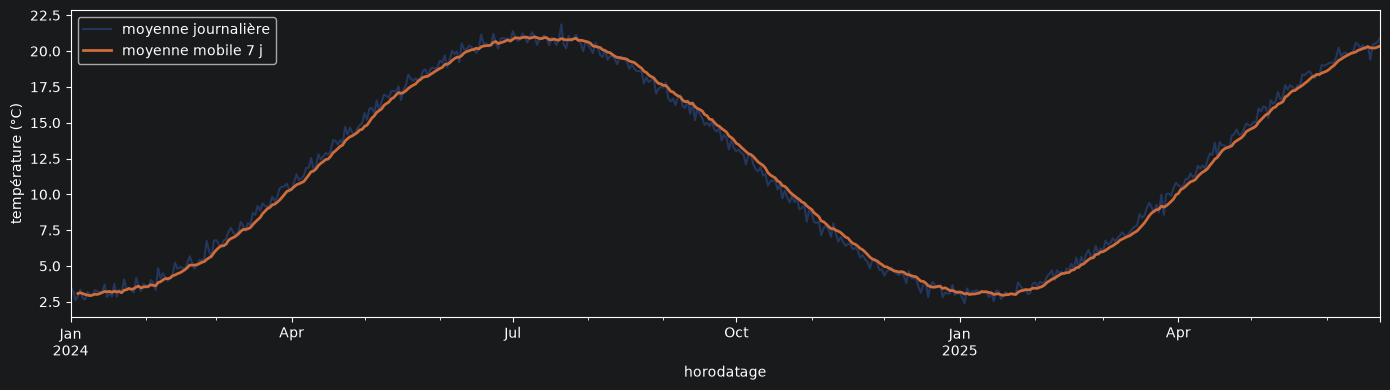

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

In [27]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.
# Filtrer CAP-B
sensor_b = (sensors[sensors['id_capteur'] == 'CAP-B']
            .set_index('horodatage')
            .sort_index())

# Grille horaire complète (freq='h' au lieu de 'H')
full_range = pd.date_range(sensor_b.index.min(),
                           sensor_b.index.max(),
                           freq='h')

# Réindexer : les heures sans mesure deviennent NaN
sensor_b_full = sensor_b.reindex(full_range)

# True = pas de mesure
missing = sensor_b_full['temperature_c'].isna()

# Identifier les blocs consécutifs de NaN
groups = (missing != missing.shift()).cumsum()

# Extraire les blocs de NaN
blocks = sensor_b_full[missing].groupby(groups)

pannes = []
for _, block in blocks:
    start = block.index.min()
    end = block.index.max()
    duration_hours = (end - start).total_seconds() / 3600

    if duration_hours > 24:
        pannes.append({
            "debut": start,
            "fin": end,
            "duree_heures": round(duration_hours, 2)
        })

pd.DataFrame(pannes)



,debut,fin,duree_heures
0,2024-06-03,2024-06-13 23:00:00,263.0


In [28]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.
# Filtrer CAP-C
sensor_c = (sensors[sensors['id_capteur'] == 'CAP-C']
            .set_index('horodatage')
            .sort_index())

# Série des températures
temp = sensor_c['temperature_c']

# Détection des changements de valeur
# True quand la valeur change, False quand elle reste identique
changes = temp != temp.shift()

# Chaque séquence de valeurs identiques reçoit un numéro unique
groups = changes.cumsum()

# Regrouper par séquence
runs = temp.groupby(groups)

bloquages = []

for _, block in runs:
    # Valeur constante ?
    if block.nunique() == 1:
        start = block.index.min()
        end = block.index.max()
        n_points = len(block)

        if n_points > 24:   # plus de 24 relevés consécutifs
            bloquages.append({
                "valeur_constante": block.iloc[0],
                "debut": start,
                "fin": end,
                "nb_releves": n_points,
                "duree_heures": round((end - start).total_seconds() / 3600, 2)
            })

pd.DataFrame(bloquages)


,valeur_constante,debut,fin,nb_releves,duree_heures
0,17.4,2024-09-10 01:00:00,2024-09-12 05:00:00,53,52.0
1,17.4,2024-09-12 07:00:00,2024-09-14 09:00:00,51,50.0


Aperçu des ventes hebdomadaires :
date_commande
2023-01-01      3042.9900
2023-01-08     23593.6660
2023-01-15     36086.0705
2023-01-22    469654.0625
2023-01-29     24827.1675
Freq: W-SUN, Name: montant, dtype: float64

Aperçu des ventes mensuelles :
date_commande
2023-01-31    573945.6610
2023-02-28    783297.5650
2023-03-31    251094.1315
2023-04-30    776771.4260
2023-05-31    151134.1735
Freq: ME, Name: montant, dtype: float64


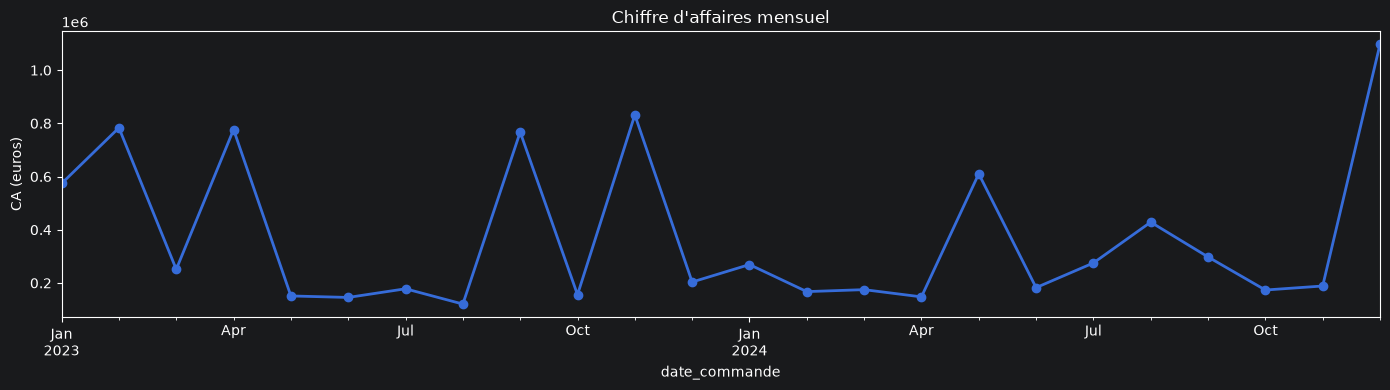

In [29]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.

# Agrégation hebdomadaire (W fonctionne toujours)
weekly_sales = (
    sales.set_index('date_commande')
         .resample('W')['montant']
         .sum()
)

print("Aperçu des ventes hebdomadaires :")
print(weekly_sales.head())

# Agrégation mensuelle (ME au lieu de M)
monthly_sales = (
    sales.set_index('date_commande')
         .resample('ME')['montant']
         .sum()
)

print("\nAperçu des ventes mensuelles :")
print(monthly_sales.head())

# Tracé du CA mensuel
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
monthly_sales.plot(ax=ax, marker='o', linewidth=2)
ax.set_title("Chiffre d'affaires mensuel")
ax.set_ylabel("CA (euros)")
plt.tight_layout()
plt.show()



---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.